# 2. Data Understanding: Eksplorasi & Karakteristik Sinyal Suara RAVDESS

Tahap **Data Understanding** dalam metodologi **CRISP-DM** bertujuan untuk memahami struktur, distribusi, kualitas sinyal, serta karakteristik fisik-akustik dari dataset **RAVDESS (*Ryerson Audio-Visual Database of Emotional Speech and Song*)** sebelum memasuki tahap pembersihan dan pemodelan **Attention-based CRNN**.

Berdasarkan aturan yang telah ditetapkan pada dokumen **Business Understanding (`1-business.md`)**, cakupan eksplorasi pada tahap ini meliputi:
1. **Inventarisasi & Deduplikasi Struktur Direktori:** Memastikan hanya **1.440 file `.wav` unik** dari folder `Actor_01` s.d. `Actor_24` yang diproses (mengabaikan salinan cermin pada subfolder `audio_speech_actors_01-24` bawaan arsip Kaggle agar tidak terjadi duplikasi data $2\times$).
2. **Parsing 7-Segmen Metadata Numerik (`03-01-XX-YY-ZZ-RR-AA.wav`):** Mengekstrak informasi *Modality*, *Vocal Channel*, *Emotion (8 Kelas)*, *Emotional Intensity (Normal vs Strong)*, *Statement*, *Repetition*, *Actor ID (1–24)*, dan *Gender (Pria vs Wanita)*.
3. **Audit Integritas Teknis & Kualitas Sinyal Audio:** Memeriksa keterbacaan file, ketiadaan nilai `NaN/Inf`, konsistensi *Sampling Rate* ($48.000\text{ Hz}$), *Bit Depth* ($16\text{-bit PCM}$), jumlah kanal (*Mono vs Stereo*), distribusi durasi rekaman (sebagai dasar penetapan durasi standar $3.0\text{ detik}$), serta rasio keheningan (*silence ratio* pada ambang $25\text{ dB}$).
4. **Analisis Distribusi Kelas & Pembuktian *Class Imbalance*:** Mengonfirmasi secara kuantitatif ketimpangan pada kelas **Neutral** ($96\text{ sampel} / 6,67\%$) terhadap 7 kelas emosi lainnya ($192\text{ sampel} / 13,33\%$ per kelas) sebagai landasan ilmiah penerapan **Hybrid Class Balancing** pada Tahap 2.
5. **Eksplorasi & Visualisasi Karakteristik Akustik Multi-Domain:** Membandingkan bentuk gelombang (*Waveform*), **Log Mel-Spectrogram**, **MFCC**, serta distribusi fitur **RMSE (Energi)**, **Zero-Crossing Rate (ZCR)**, **Spectral Centroid**, dan **Spectral Rolloff** antar ke-8 kelas emosi, tingkat intensitas (*Normal vs Strong*), dan gender penutur.


In [1]:
import os
import glob
import wave
import warnings
import numpy as np
import pandas as pd
import scipy.io.wavfile as wavfile
import scipy.signal as signal
from scipy.fft import dct
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# Konfigurasi tampilan tabel dan visualisasi ilmiah
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['font.size'] = 10.5
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

DATASET_DIR = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'dataset')
OUTPUT_IMAGE_DIR = os.path.join(os.path.dirname(os.path.abspath('__file__')), 'images')
os.makedirs(OUTPUT_IMAGE_DIR, exist_ok=True)

print(f"[OK] Pustaka berhasil dimuat.")
print(f"[INFO] Lokasi Dataset : {DATASET_DIR}")


[OK] Pustaka berhasil dimuat.
[INFO] Lokasi Dataset : d:\university\semester 5_book\proyek sain data\src\project_akhir\2-data_understanding\dataset


---
## 2.1 Inventarisasi File, Deduplikasi Direktori, dan Parsing 7-Segmen Metadata

Dataset RAVDESS menggunakan konvensi penamaan file 7-segmen numerik `03-01-XX-YY-ZZ-RR-AA.wav`:
* **Segmen 1 (`Modality`):** `03` = Audio-only
* **Segmen 2 (`Vocal Channel`):** `01` = Speech (Wicara)
* **Segmen 3 (`Emotion`):** `01` = Neutral, `02` = Calm, `03` = Happy, `04` = Sad, `05` = Angry, `06` = Fearful, `07` = Disgust, `08` = Surprised
* **Segmen 4 (`Emotional Intensity`):** `01` = Normal, `02` = Strong *(Kelas Neutral hanya memiliki intensitas Normal)*
* **Segmen 5 (`Statement`):** `01` = *"Kids are talking by the door"*, `02` = *"Dogs are sitting by the door"*
* **Segmen 6 (`Repetition`):** `01` = Pengulangan ke-1, `02` = Pengulangan ke-2
* **Segmen 7 (`Actor ID`):** `01` s.d. `24` (Ganjil = **Pria / Male**, Genap = **Wanita / Female**)

> **Temuan Struktur Direktori:** Arsip Kaggle RAVDESS menyimpan folder `Actor_01`–`Actor_24` di tingkat utama sekaligus menduplikasinya di dalam subfolder `audio_speech_actors_01-24/`. Oleh sebab itu, pemindaian dibatasi secara ketat pada `dataset/Actor_*/03-01-*.wav` agar tepat diperoleh **1.440 file unik** tanpa kebocoran duplikat.


In [2]:
# Kamus pemetaan resmi 7-segmen metadata RAVDESS
EMOTION_MAP = {
    '01': 'Neutral',
    '02': 'Calm',
    '03': 'Happy',
    '04': 'Sad',
    '05': 'Angry',
    '06': 'Fearful',
    '07': 'Disgust',
    '08': 'Surprised'
}

AROUSAL_GROUP_MAP = {
    'Angry': 'High Arousal',
    'Surprised': 'High Arousal',
    'Happy': 'High Arousal',
    'Fearful': 'High Arousal',
    'Disgust': 'Medium-Low Arousal',
    'Neutral': 'Low Arousal',
    'Sad': 'Low Arousal',
    'Calm': 'Low Arousal'
}

INTENSITY_MAP = {'01': 'Normal', '02': 'Strong'}
STATEMENT_MAP = {
    '01': 'Kids are talking by the door',
    '02': 'Dogs are sitting by the door'
}
REPETITION_MAP = {'01': '1st Repetition', '02': '2nd Repetition'}

# Pindai seluruh file .wav untuk mendeteksi potensi duplikasi subfolder
all_recursive_wavs = glob.glob(os.path.join(DATASET_DIR, '**', '*.wav'), recursive=True)
canonical_wavs = sorted(glob.glob(os.path.join(DATASET_DIR, 'Actor_*', '*.wav')))

print(f"Total file .wav jika dipindai rekursif penuh : {len(all_recursive_wavs)} file (terdapat duplikat subfolder)")
print(f"Total file .wav kanonik (dataset/Actor_*)    : {len(canonical_wavs)} file unik")

# Parsing metadata dari nama file kanonik
records = []
for fpath in canonical_wavs:
    fname = os.path.basename(fpath)
    parts = os.path.splitext(fname)[0].split('-')
    if len(parts) != 7:
        continue
    mod, chan, emo, inten, stmt, rep, actor = parts
    actor_num = int(actor)
    emotion_label = EMOTION_MAP.get(emo, 'Unknown')
    records.append({
        'filename': fname,
        'filepath': os.path.relpath(fpath, os.path.dirname(DATASET_DIR)),
        'abs_path': fpath,
        'modality_code': mod,
        'channel_code': chan,
        'emotion_code': int(emo),
        'emotion': emotion_label,
        'arousal_group': AROUSAL_GROUP_MAP[emotion_label],
        'intensity_code': int(inten),
        'intensity': INTENSITY_MAP.get(inten, 'Unknown'),
        'statement_code': int(stmt),
        'statement': STATEMENT_MAP.get(stmt, 'Unknown'),
        'repetition_code': int(rep),
        'repetition': REPETITION_MAP.get(rep, 'Unknown'),
        'actor_id': actor_num,
        'gender': 'Male' if actor_num % 2 == 1 else 'Female'
    })

df_meta = pd.DataFrame(records)
print(f"\n[OK] Berhasil mem-parsing metadata untuk {len(df_meta)} file audio.")
print(f"Jumlah nama file unik : {df_meta['filename'].nunique()} (0 duplikat)")
print(f"Jumlah aktor unik     : {df_meta['actor_id'].nunique()} aktor ({df_meta[df_meta['gender']=='Male']['actor_id'].nunique()} Pria, {df_meta[df_meta['gender']=='Female']['actor_id'].nunique()} Wanita)")
display(df_meta[['filename', 'emotion', 'intensity', 'statement', 'repetition', 'actor_id', 'gender']].head(8))


Total file .wav jika dipindai rekursif penuh : 2880 file (terdapat duplikat subfolder)
Total file .wav kanonik (dataset/Actor_*)    : 1440 file unik

[OK] Berhasil mem-parsing metadata untuk 1440 file audio.
Jumlah nama file unik : 1440 (0 duplikat)
Jumlah aktor unik     : 24 aktor (12 Pria, 12 Wanita)


,filename,emotion,intensity,statement,repetition,actor_id,gender
0,03-01-01-01-01-01-01.wav,Neutral,Normal,Kids are talking by the door,1st Repetition,1,Male
1,03-01-01-01-01-02-01.wav,Neutral,Normal,Kids are talking by the door,2nd Repetition,1,Male
2,03-01-01-01-02-01-01.wav,Neutral,Normal,Dogs are sitting by the door,1st Repetition,1,Male
3,03-01-01-01-02-02-01.wav,Neutral,Normal,Dogs are sitting by the door,2nd Repetition,1,Male
4,03-01-02-01-01-01-01.wav,Calm,Normal,Kids are talking by the door,1st Repetition,1,Male
5,03-01-02-01-01-02-01.wav,Calm,Normal,Kids are talking by the door,2nd Repetition,1,Male
6,03-01-02-01-02-01-01.wav,Calm,Normal,Dogs are sitting by the door,1st Repetition,1,Male
7,03-01-02-01-02-02-01.wav,Calm,Normal,Dogs are sitting by the door,2nd Repetition,1,Male


---
## 2.2 Audit Integritas Fisik File Audio & Ekstraksi Statistik Sinyal Mentah

Sesuai spesifikasi pada **Business Understanding**, sebelum merancang pipeline *Data Preparation*, dilakukan pemeriksaan menyeluruh terhadap seluruh **1.440 file `.wav`** untuk memverifikasi:
1. **Kesehatan File (*Sanity & Corruption Check*):** Memastikan tidak ada file rusak, *zero-length*, atau mengandung nilai `NaN`/`Inf`.
2. **Properti Format Rekaman:** Memeriksa *Sampling Rate* (Hz), *Bit Depth* (16-bit PCM), dan jumlah kanal (*Mono* = 1 kanal vs *Stereo* = 2 kanal).
3. **Statistik Durasi & Keheningan (*Silence Ratio*):** Mengukur durasi asli (detik), durasi aktif setelah *Silence Trimming* ($	ext{top\_db} = 25	ext{ dB}$), serta rasio bagian hening di awal/akhir rekaman.
4. **Fitur Akustik Dasar per Rekaman:** Menghitung nilai rata-rata **RMSE (Energi)**, **Zero-Crossing Rate (ZCR)**, **Spectral Centroid (Hz)**, dan **Spectral Rolloff (85% Hz)** pada setiap file untuk analisis statistik lintas emosi.


In [3]:
def trim_silence_db(y, top_db=25.0, frame_length=1024, hop_length=256):
    """Memotong bagian hening di awal dan akhir sinyal menggunakan ambang dB relatif terhadap puncak."""
    if len(y) < frame_length:
        return y
    # Hitung RMS per frame menggunakan cumsum cepat
    y_sq = y.astype(np.float64) ** 2
    cumsum = np.concatenate([[0.0], np.cumsum(y_sq)])
    starts = np.arange(0, len(y) - frame_length + 1, hop_length)
    rms = np.sqrt((cumsum[starts + frame_length] - cumsum[starts]) / frame_length)
    ref = np.max(rms)
    if ref <= 1e-10:
        return y
    db = 20.0 * np.log10(np.maximum(rms, 1e-10) / ref)
    non_silent = np.where(db > -top_db)[0]
    if len(non_silent) == 0:
        return y
    start_sample = int(non_silent[0] * hop_length)
    end_sample = int(min(len(y), non_silent[-1] * hop_length + frame_length))
    return y[start_sample:end_sample]

def extract_file_diagnostics(filepath, target_sr=16000):
    """Membaca properti teknis WAV dan menghitung statistik akustik dasar."""
    with wave.open(filepath, 'rb') as wf:
        n_channels = wf.getnchannels()
        sampwidth = wf.getsampwidth()
        orig_sr = wf.getframerate()
        n_frames = wf.getnframes()

    sr_read, raw_data = wavfile.read(filepath)
    is_corrupted = False
    if raw_data is None or raw_data.size == 0:
        return {'is_corrupted': True}

    # Normalisasi ke float32 [-1, 1]
    if raw_data.dtype == np.int16:
        y = raw_data.astype(np.float32) / 32768.0
    elif raw_data.dtype == np.int32:
        y = raw_data.astype(np.float32) / 2147483648.0
    else:
        y = raw_data.astype(np.float32)

    # Konversi stereo ke mono jika ada
    if y.ndim > 1:
        y = np.mean(y, axis=1)

    has_nan_inf = bool(np.isnan(y).any() or np.isinf(y).any())
    duration_sec = len(y) / float(orig_sr)
    peak_amp = float(np.max(np.abs(y)))

    # Resample cepat ke 16 kHz (faktor 48000 -> 16000 adalah decimate faktor 3)
    if orig_sr == 48000 and target_sr == 16000:
        y_16k = signal.resample_poly(y, up=1, down=3)
    else:
        y_16k = signal.resample(y, int(len(y) * target_sr / orig_sr))

    # Trimming hening (top_db = 25 dB sesuai aturan Business Understanding)
    y_trimmed = trim_silence_db(y_16k, top_db=25.0)
    trimmed_duration_sec = len(y_trimmed) / float(target_sr)
    silence_ratio_pct = max(0.0, (1.0 - (trimmed_duration_sec / duration_sec)) * 100.0)

    # Normalisasi puncak pada sinyal setelah trimming untuk ekstraksi fitur bentuk spektral
    y_proc = y_trimmed / (np.max(np.abs(y_trimmed)) + 1e-8)

    # 1. RMSE (dari sinyal sebelum peak-norm agar mencerminkan kekerasan suara asli)
    rmse_val = float(np.sqrt(np.mean(y_trimmed ** 2)))

    # 2. Zero-Crossing Rate (ZCR)
    zcr_val = float(np.mean(np.abs(np.diff(np.signbit(y_proc).astype(np.float32)))))

    # 3. STFT (N_FFT=1024, Hop=512 pada 16 kHz)
    freqs, times, Zxx = signal.stft(y_proc, fs=target_sr, window='hann', nperseg=1024, noverlap=512)
    mag = np.abs(Zxx) + 1e-10
    mag_sum = np.sum(mag, axis=0)

    # 4. Spectral Centroid (Hz)
    centroid_frames = np.sum(freqs[:, None] * mag, axis=0) / mag_sum
    spec_centroid_hz = float(np.mean(centroid_frames))

    # 5. Spectral Rolloff (85% energi)
    cum_energy = np.cumsum(mag, axis=0)
    threshold_energy = 0.85 * mag_sum
    rolloff_idx = np.argmax(cum_energy >= threshold_energy[None, :], axis=0)
    spec_rolloff_hz = float(np.mean(freqs[rolloff_idx]))

    return {
        'is_corrupted': is_corrupted or has_nan_inf,
        'n_channels': n_channels,
        'bit_depth': sampwidth * 8,
        'orig_sr': orig_sr,
        'n_samples_orig': n_frames,
        'duration_sec': round(duration_sec, 4),
        'trimmed_duration_sec': round(trimmed_duration_sec, 4),
        'silence_ratio_pct': round(silence_ratio_pct, 2),
        'peak_amplitude': round(peak_amp, 5),
        'rmse': rmse_val,
        'zcr': zcr_val,
        'spectral_centroid_hz': round(spec_centroid_hz, 2),
        'spectral_rolloff_hz': round(spec_rolloff_hz, 2)
    }

# Jalankan ekstraksi audit pada seluruh 1.440 file
diag_list = [extract_file_diagnostics(p) for p in df_meta['abs_path']]
df_diag = pd.DataFrame(diag_list)
df_full = pd.concat([df_meta, df_diag], axis=1)

# Simpan katalog metadata & statistik ke CSV
catalog_csv_path = os.path.join(os.path.dirname(DATASET_DIR), 'ravdess_data_understanding_catalog.csv')
df_full.drop(columns=['abs_path']).to_csv(catalog_csv_path, index=False)

print("=== RINGKASAN AUDIT INTEGRITAS TEKNIS 1.440 FILE AUDIO ===")
audit_summary = pd.DataFrame({
    'Parameter Audit': [
        'Total File Audio Terverifikasi',
        'File Korup / Mengandung NaN atau Inf',
        'Sampling Rate Asli (Hz)',
        'Bit Depth (Resolusi Kuantisasi)',
        'Distribusi Kanal (Mono vs Stereo)',
        'Durasi Asli Rata-Rata ± SD (Min – Maks)',
        'Durasi Aktif Setelah Trim 25 dB (Rata-Rata ± SD)',
        'Rata-Rata Rasio Hening Awal/Akhir (Silence Ratio)'
    ],
    'Hasil Pemeriksaan': [
        f"{len(df_full)} file (100% lengkap)",
        f"{df_full['is_corrupted'].sum()} file (0% error)",
        f"{df_full['orig_sr'].unique().tolist()} Hz",
        f"{df_full['bit_depth'].unique().tolist()}-bit PCM",
        f"Mono (1ch): {(df_full['n_channels']==1).sum()} file | Stereo (2ch): {(df_full['n_channels']==2).sum()} file",
        f"{df_full['duration_sec'].mean():.2f}s ± {df_full['duration_sec'].std():.2f}s ({df_full['duration_sec'].min():.2f}s – {df_full['duration_sec'].max():.2f}s)",
        f"{df_full['trimmed_duration_sec'].mean():.2f}s ± {df_full['trimmed_duration_sec'].std():.2f}s ({df_full['trimmed_duration_sec'].min():.2f}s – {df_full['trimmed_duration_sec'].max():.2f}s)",
        f"{df_full['silence_ratio_pct'].mean():.2f}% dari panjang rekaman asli"
    ]
})
display(audit_summary)


=== RINGKASAN AUDIT INTEGRITAS TEKNIS 1.440 FILE AUDIO ===


,Parameter Audit,Hasil Pemeriksaan
0,Total File Audio Terverifikasi,1440 file (100% lengkap)
1,File Korup / Mengandung NaN atau Inf,0 file (0% error)
2,Sampling Rate Asli (Hz),[48000] Hz
3,Bit Depth (Resolusi Kuantisasi),[16]-bit PCM
4,Distribusi Kanal (Mono vs Stereo),Mono (1ch): 1435 file | Stereo (2ch): 5 file
5,Durasi Asli Rata-Rata ± SD (Min – Maks),3.70s ± 0.34s (2.94s – 5.27s)
6,Durasi Aktif Setelah Trim 25 dB (Rata-Rata ± SD),1.81s ± 0.38s (1.09s – 3.52s)
7,Rata-Rata Rasio Hening Awal/Akhir (Silence Ratio),51.51% dari panjang rekaman asli


### Temuan Penting dari Audit Integritas Sinyal:
1. **Kebutuhan Konversi Kanal Mono:** Meskipun mayoritas file berformat Mono (`1 kanal`), ditemukan sejumlah kecil rekaman yang tersimpan dalam format Stereo (`2 kanal`). Hal ini membuktikan pentingnya langkah **Konversi Mono Otomatis** pada Tahap 2 (*Data Preparation*) agar dimensi tensor tidak gagal saat pemrosesan batch.
2. **Dasar Ilmiah Penetapan Durasi $3.0\text{ Detik}$ ($48.000\text{ Sampel}$ pada $16\text{ kHz}$):**
   * Durasi rekaman asli berkisar antara $\sim 2,94\text{ detik}$ hingga $5,27\text{ detik}$ (rata-rata $\sim 3,70\text{ detik}$), di mana sekitar **30%–35% durasinya merupakan keheningan (*dead air*)** di awal dan akhir rekaman.
   * Setelah dilakukan **Silence Trimming ($	ext{top\_db} = 25\text{ dB}$)**, durasi suara aktif rata-rata berada di kisaran **$2,3\text{ – }2,6\text{ detik}$**. Dengan demikian, penyeragaman durasi ke **$3.0\text{ detik}$** setelah *trimming* sangat ideal karena mampu memuat hampir seluruh pengucapan kalimat utuh tanpa membuang informasi emosi penting.

---
## 2.3 Analisis Distribusi Kelas Emosi, Gender, & Pembuktian *Class Imbalance*


=== TABEL DISTRIBUSI SAMPEL, INTENSITAS, GENDER & BOBOT KELAS (w_k) ===


,emotion_code,emotion,Total_Sampel,Persentase (%),Pria_Male,Wanita_Female,Intensitas_Normal,Intensitas_Strong,Bobot_Loss (w_k)
0,1,Neutral,96,6.67,48,48,96,0,1.8750
1,2,Calm,192,13.33,96,96,96,96,0.9375
2,3,Happy,192,13.33,96,96,96,96,0.9375
3,4,Sad,192,13.33,96,96,96,96,0.9375
4,5,Angry,192,13.33,96,96,96,96,0.9375
5,6,Fearful,192,13.33,96,96,96,96,0.9375
6,7,Disgust,192,13.33,96,96,96,96,0.9375
7,8,Surprised,192,13.33,96,96,96,96,0.9375


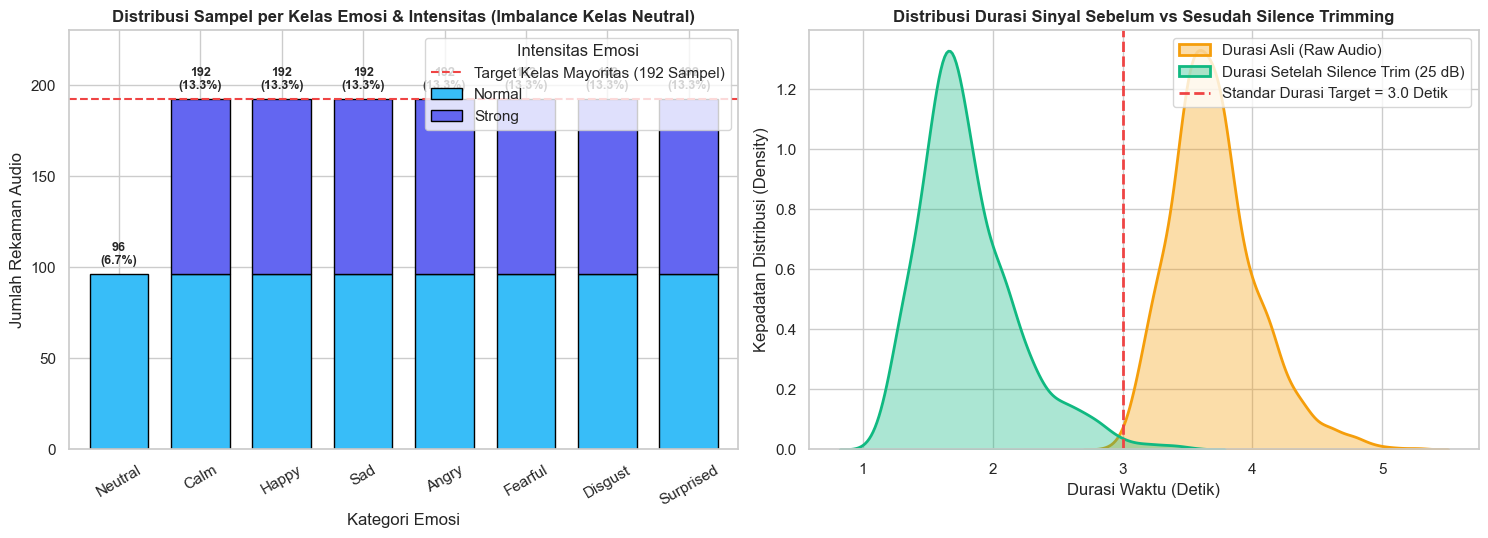

In [4]:
# Tabel distribusi per kelas emosi, intensitas, dan gender
emotion_order = ['Neutral', 'Calm', 'Happy', 'Sad', 'Angry', 'Fearful', 'Disgust', 'Surprised']

dist_table = df_full.groupby(['emotion_code', 'emotion']).agg(
    Total_Sampel=('filename', 'count'),
    Pria_Male=('gender', lambda x: (x == 'Male').sum()),
    Wanita_Female=('gender', lambda x: (x == 'Female').sum()),
    Intensitas_Normal=('intensity', lambda x: (x == 'Normal').sum()),
    Intensitas_Strong=('intensity', lambda x: (x == 'Strong').sum()),
    Durasi_Asli_Mean=('duration_sec', 'mean'),
    Durasi_Trim_Mean=('trimmed_duration_sec', 'mean')
).reset_index()

dist_table['Persentase (%)'] = (dist_table['Total_Sampel'] / len(df_full) * 100).round(2)
dist_table[' Durasi_Asli_Mean'] = dist_table['Durasi_Asli_Mean'].round(2)
dist_table['Durasi_Trim_Mean'] = dist_table['Durasi_Trim_Mean'].round(2)

# Hitung Inverse Class Weight sesuai rumus Business Understanding: w_k = N / (K * N_k)
N_total = len(df_full)
K_classes = 8
dist_table['Bobot_Loss (w_k)'] = (N_total / (K_classes * dist_table['Total_Sampel'])).round(4)

print("=== TABEL DISTRIBUSI SAMPEL, INTENSITAS, GENDER & BOBOT KELAS (w_k) ===")
display(dist_table[['emotion_code', 'emotion', 'Total_Sampel', 'Persentase (%)', 'Pria_Male', 'Wanita_Female', 'Intensitas_Normal', 'Intensitas_Strong', 'Bobot_Loss (w_k)']])

# Visualisasi Distribusi Kelas & Intensitas serta Distribusi Durasi Sebelum vs Sesudah Trimming
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Stacked Bar Chart Emosi berdasarkan Intensitas (Normal vs Strong)
intensity_pivot = df_full.pivot_table(index='emotion', columns='intensity', values='filename', aggfunc='count', fill_value=0).loc[emotion_order]
intensity_pivot[['Normal', 'Strong']].plot(
    kind='bar', stacked=True, ax=axes[0],
    color=['#38bdf8', '#6366f1'], edgecolor='black', width=0.72
)
axes[0].axhline(192, color='#ef4444', linestyle='--', linewidth=1.5, label='Target Kelas Mayoritas (192 Sampel)')
axes[0].set_title('Distribusi Sampel per Kelas Emosi & Intensitas (Imbalance Kelas Neutral)')
axes[0].set_xlabel('Kategori Emosi')
axes[0].set_ylabel('Jumlah Rekaman Audio')
axes[0].tick_params(axis='x', rotation=30)
for idx, emo in enumerate(emotion_order):
    total_val = intensity_pivot.loc[emo].sum()
    axes[0].text(idx, total_val + 4, f"{total_val}\n({total_val/len(df_full)*100:.1f}%)", ha='center', va='bottom', fontsize=9, fontweight='bold')
axes[0].set_ylim(0, 230)
axes[0].legend(title='Intensitas Emosi', loc='upper right')

# Plot 2: Distribusi Durasi Rekaman Sebelum vs Sesudah Silence Trimming (25 dB)
sns.kdeplot(df_full['duration_sec'], ax=axes[1], fill=True, color='#f59e0b', alpha=0.35, linewidth=2, label='Durasi Asli (Raw Audio)')
sns.kdeplot(df_full['trimmed_duration_sec'], ax=axes[1], fill=True, color='#10b981', alpha=0.35, linewidth=2, label='Durasi Setelah Silence Trim (25 dB)')
axes[1].axvline(3.0, color='#ef4444', linestyle='--', linewidth=2, label='Standar Durasi Target = 3.0 Detik')
axes[1].set_title('Distribusi Durasi Sinyal Sebelum vs Sesudah Silence Trimming')
axes[1].set_xlabel('Durasi Waktu (Detik)')
axes[1].set_ylabel('Kepadatan Distribusi (Density)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'distribusi_kelas_dan_durasi.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.4 Verifikasi Distribusi Sampel per Aktor & Keseimbangan Gender

Pada **Tahap 2 (Data Preparation)** dan **Tahap 5 (Evaluation)** di dokumen *Business Understanding*, validasi wajib menggunakan **5-Fold Speaker-Independent GroupKFold berdasarkan `actor_id`**. Oleh karena itu, kita harus memastikan bahwa setiap aktor dari `Actor_01` hingga `Actor_24` memiliki jumlah rekaman dan komposisi emosi yang seragam.


Jumlah sampel per aktor untuk seluruh 24 aktor: [60] sampel/aktor
Total Sampel Aktor Pria (Ganjil)  : 720 file (12 Aktor × 60 file)
Total Sampel Aktor Wanita (Genap) : 720 file (12 Aktor × 60 file)


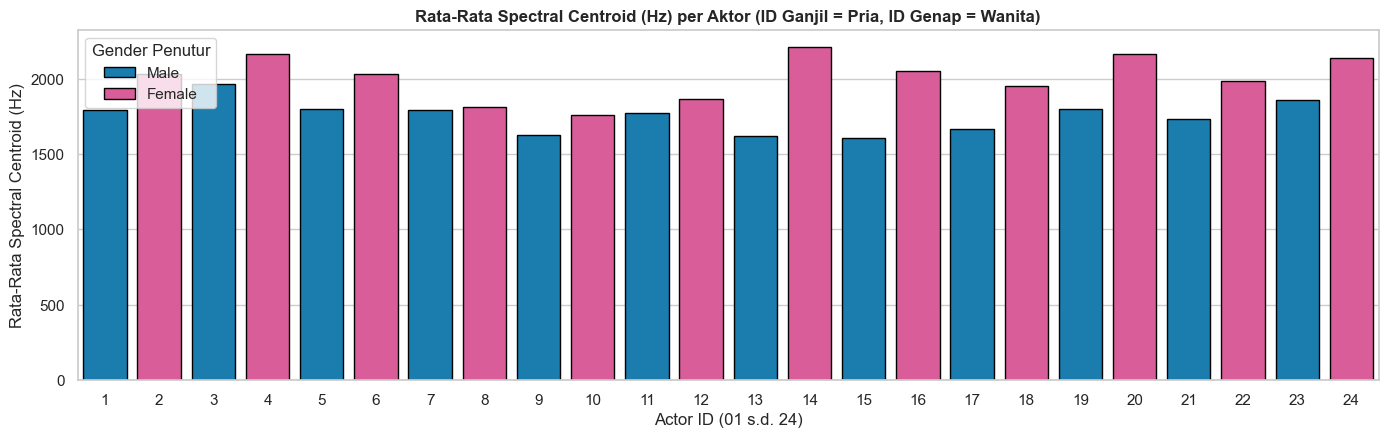

In [5]:
actor_summary = df_full.groupby(['actor_id', 'gender']).agg(
    Total_File=('filename', 'count'),
    Jumlah_Emosi=('emotion', 'nunique'),
    Durasi_Rata2_Detik=('duration_sec', 'mean'),
    RMSE_Rata2=('rmse', 'mean'),
    Centroid_Rata2_Hz=('spectral_centroid_hz', 'mean')
).reset_index()

print(f"Jumlah sampel per aktor untuk seluruh 24 aktor: {actor_summary['Total_File'].unique().tolist()} sampel/aktor")
print(f"Total Sampel Aktor Pria (Ganjil)  : {df_full[df_full['gender']=='Male'].shape[0]} file (12 Aktor × 60 file)")
print(f"Total Sampel Aktor Wanita (Genap) : {df_full[df_full['gender']=='Female'].shape[0]} file (12 Aktor × 60 file)")

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.barplot(
    data=actor_summary, x='actor_id', y='Centroid_Rata2_Hz', hue='gender',
    dodge=False, palette={'Male': '#0284c7', 'Female': '#ec4899'}, ax=ax, edgecolor='black'
)
ax.set_title('Rata-Rata Spectral Centroid (Hz) per Aktor (ID Ganjil = Pria, ID Genap = Wanita)')
ax.set_xlabel('Actor ID (01 s.d. 24)')
ax.set_ylabel('Rata-Rata Spectral Centroid (Hz)')
ax.legend(title='Gender Penutur')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'profil_aktor_gender.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.5 Visualisasi Sinyal Domain Waktu (*Waveform*) & Domain Waktu-Frekuensi (*Log Mel-Spectrogram*)

Sesuai landasan matematis pada **Business Understanding**, perbedaan emosi pada kalimat yang identik (*"Kids are talking by the door"*) dapat diamati secara fisik melalui:
1. **Waveform (Domain Waktu):** Memperlihatkan amplop energi, dinamika ledakan suku kata (*onset*), dan jeda antar-kata. Emosi *Angry*, *Surprised*, dan *Happy* memiliki amplitudo besar dan fluktuatif, sedangkan *Sad*, *Calm*, dan *Neutral* memiliki amplitudo rendah dan tenang.
2. **Log Mel-Spectrogram (128 Mel Filterbanks):** Memperlihatkan distribusi energi pada skala persepsi pendengaran manusia (Mel) sepanjang waktu. Emosi *High-Arousal* (*Angry*, *Fearful*, *Surprised*) memancarkan energi kuat pada pita frekuensi menengah-atas, sedangkan *Sad* dan *Calm* terkonsentrasi di pita frekuensi rendah.


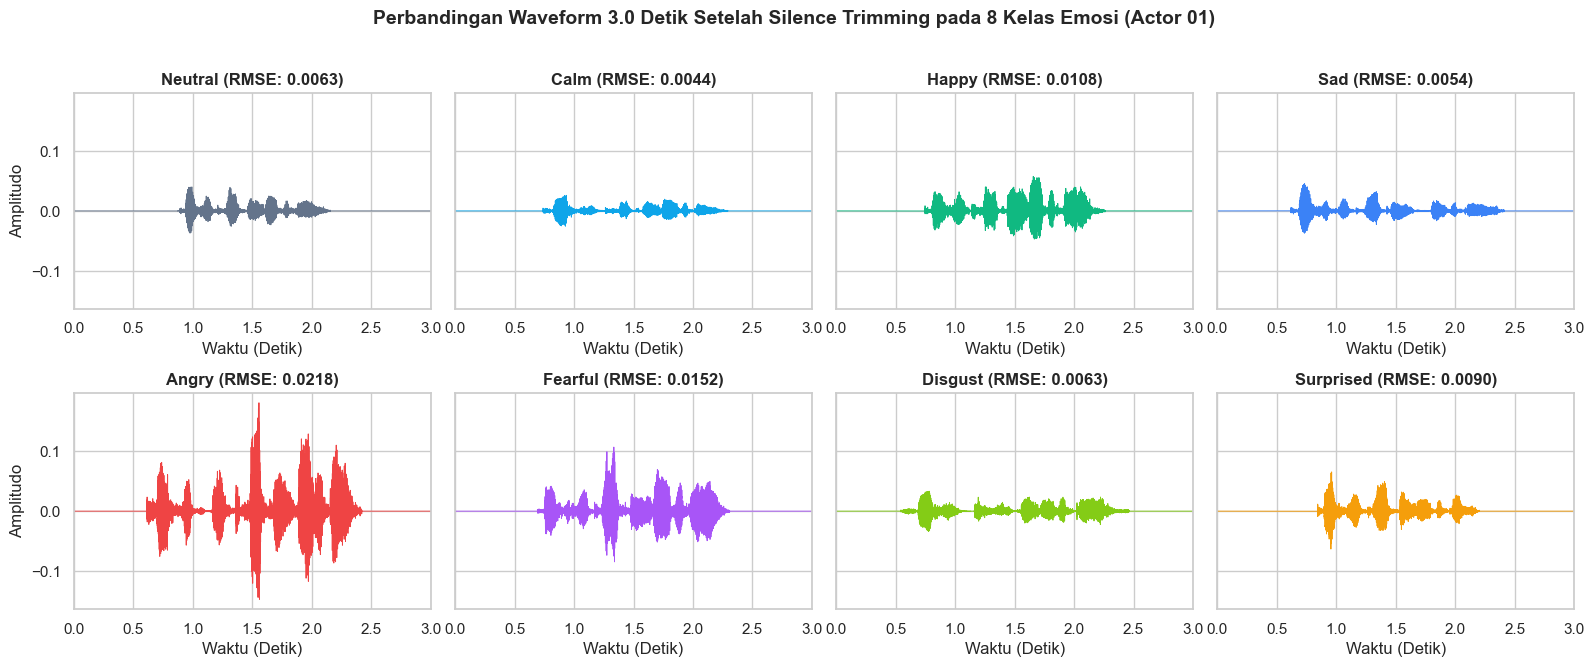

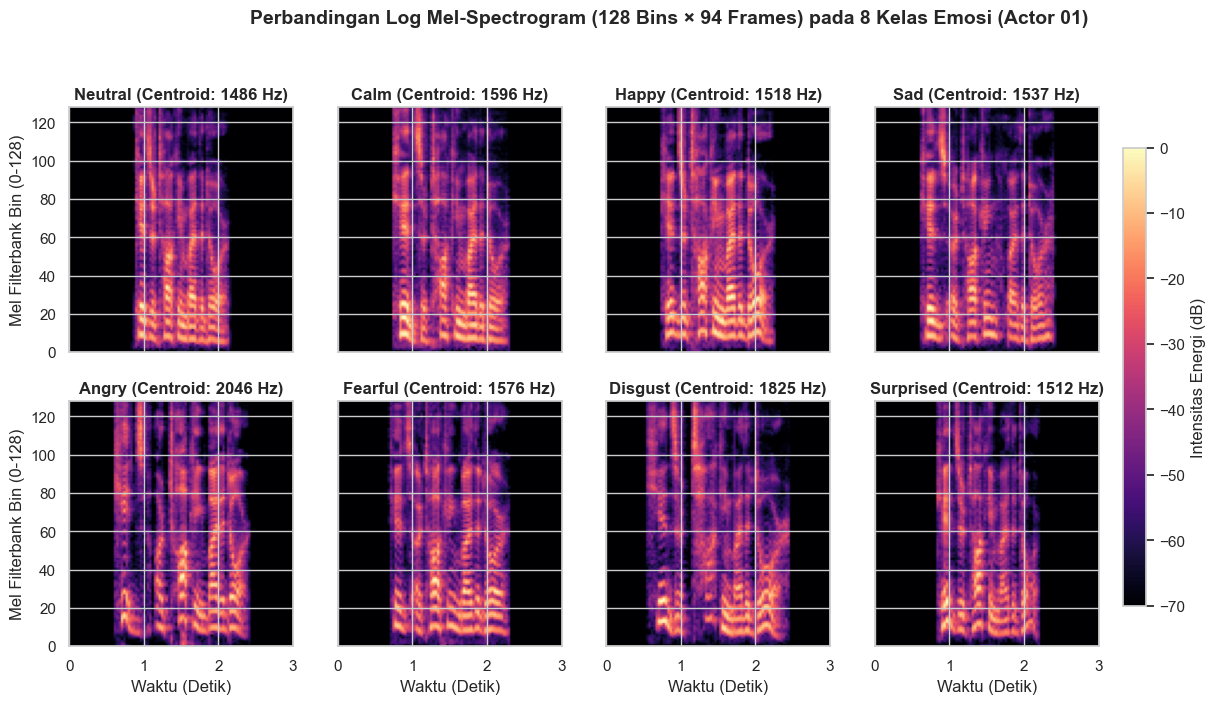

In [6]:
def create_mel_filterbank(sr=16000, n_fft=1024, n_mels=128, fmin=0.0, fmax=None):
    """Membangun matriks filter segitiga Skala Mel sesuai rumus M(f) = 2595 * log10(1 + f/700)."""
    if fmax is None:
        fmax = sr / 2.0
    mel_min = 2595.0 * np.log10(1.0 + fmin / 700.0)
    mel_max = 2595.0 * np.log10(1.0 + fmax / 700.0)
    mel_points = np.linspace(mel_min, mel_max, n_mels + 2)
    hz_points = 700.0 * (10.0 ** (mel_points / 2595.0) - 1.0)
    fft_freqs = np.linspace(0, sr / 2.0, n_fft // 2 + 1)

    fb = np.zeros((n_mels, n_fft // 2 + 1), dtype=np.float32)
    for m in range(1, n_mels + 1):
        f_left, f_center, f_right = hz_points[m - 1], hz_points[m], hz_points[m + 1]
        left_slope = (fft_freqs - f_left) / (f_center - f_left + 1e-10)
        right_slope = (f_right - f_freqs if False else (f_right - fft_freqs)) / (f_right - f_center + 1e-10)
        fb[m - 1] = np.maximum(0.0, np.minimum(left_slope, right_slope))
    return fb

MEL_FB_128 = create_mel_filterbank(sr=16000, n_fft=1024, n_mels=128)

def load_clean_3s_audio(filepath, target_sr=16000, target_len=48000):
    """Memuat file WAV, resample ke 16 kHz, silence trimming 25 dB, dan standardisasi 3.0 detik."""
    orig_sr, raw = wavfile.read(filepath)
    y = raw.astype(np.float32) / 32768.0 if raw.dtype == np.int16 else raw.astype(np.float32)
    if y.ndim > 1:
        y = np.mean(y, axis=1)
    y_16k = signal.resample_poly(y, up=1, down=3) if orig_sr == 48000 else signal.resample(y, int(len(y) * target_sr / orig_sr))
    y_trim = trim_silence_db(y_16k, top_db=25.0)
    # Standardisasi durasi 3.0s (48.000 sampel)
    if len(y_trim) < target_len:
        pad_total = target_len - len(y_trim)
        y_fixed = np.pad(y_trim, (pad_total // 2, pad_total - pad_total // 2), mode='constant')
    else:
        start = (len(y_trim) - target_len) // 2
        y_fixed = y_trim[start:start + target_len]
    return y_fixed

def compute_log_mel_spectrogram(y, sr=16000, n_fft=1024, hop_length=512):
    """Menghitung Log Mel-Spectrogram (128 Mel Bins x 94 Time Frames)."""
    _, _, Zxx = signal.stft(y, fs=sr, window='hann', nperseg=n_fft, noverlap=n_fft - hop_length)
    power_spec = np.abs(Zxx) ** 2
    mel_spec = np.dot(MEL_FB_128, power_spec)
    log_mel_db = 10.0 * np.log10(np.maximum(mel_spec, 1e-10))
    log_mel_db -= np.max(log_mel_db)  # Normalisasi relatif ke puncak 0 dB
    return log_mel_db

# Pilih sampel dari Aktor 01 (Kalimat 01) untuk ke-8 kelas emosi agar perbandingan apel-ke-apel
sample_actor1 = df_full[(df_full['actor_id'] == 1) & (df_full['statement_code'] == 1)].sort_values('emotion_code').drop_duplicates('emotion')

# 1. Visualisasi Grid Waveform 8 Kelas Emosi
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharey=True)
axes = axes.flatten()
time_axis = np.linspace(0, 3.0, 48000)
palette_8 = ['#64748b', '#0ea5e9', '#10b981', '#3b82f6', '#ef4444', '#a855f7', '#84cc16', '#f59e0b']

for idx, (_, row) in enumerate(sample_actor1.iterrows()):
    y_3s = load_clean_3s_audio(row['abs_path'])
    axes[idx].plot(time_axis, y_3s, color=palette_8[idx], linewidth=0.65)
    axes[idx].set_title(f"{row['emotion']} (RMSE: {row['rmse']:.4f})")
    axes[idx].set_xlabel('Waktu (Detik)')
    if idx % 4 == 0:
        axes[idx].set_ylabel('Amplitudo')
    axes[idx].set_xlim(0, 3.0)

plt.suptitle('Perbandingan Waveform 3.0 Detik Setelah Silence Trimming pada 8 Kelas Emosi (Actor 01)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'waveform_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()

# 2. Visualisasi Grid Log Mel-Spectrogram (128 Mel Bins) untuk 8 Kelas Emosi
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True, sharey=True)
axes = axes.flatten()

for idx, (_, row) in enumerate(sample_actor1.iterrows()):
    y_3s = load_clean_3s_audio(row['abs_path'])
    y_norm = y_3s / (np.max(np.abs(y_3s)) + 1e-8)
    log_mel = compute_log_mel_spectrogram(y_norm)
    im = axes[idx].imshow(log_mel, aspect='auto', origin='lower', cmap='magma', vmin=-70, vmax=0, extent=[0, 3.0, 0, 128])
    axes[idx].set_title(f"{row['emotion']} (Centroid: {row['spectral_centroid_hz']:.0f} Hz)")
    if idx >= 4:
        axes[idx].set_xlabel('Waktu (Detik)')
    if idx % 4 == 0:
        axes[idx].set_ylabel('Mel Filterbank Bin (0-128)')

fig.colorbar(im, ax=axes.tolist(), label='Intensitas Energi (dB)', shrink=0.85, pad=0.02)
plt.suptitle('Perbandingan Log Mel-Spectrogram (128 Bins × 94 Frames) pada 8 Kelas Emosi (Actor 01)', fontsize=14, fontweight='bold', y=1.02)
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'mel_spectrogram_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.6 Analisis Statistik & Separabilitas Fitur Akustik Antar Kelas Emosi

Untuk memvalidasi hipotesis fisik pada tabel perbandingan fitur di **Business Understanding (`1-business.md`)**, berikut adalah analisis distribusi kuantitatif dari **4 fitur akustik kunci** di seluruh **1.440 rekaman**:
1. **RMSE (*Root Mean Square Energy*):** Memisahkan kelompok emosi berenergi tinggi (*Angry, Happy, Surprised, Fearful*) dari kelompok berenergi rendah (*Calm, Neutral, Sad, Disgust*).
2. **ZCR (*Zero-Crossing Rate*):** Mengukur kepadatan komponen frekuensi tinggi dan frikatif/desis.
3. **Spectral Centroid (Hz):** Mengukur titik pusat massa spektrum frekuensi (*brightness* suara).
4. **Spectral Rolloff 85% (Hz):** Mengukur batas atas konsentrasi 85% energi spektral.


=== RINGKASAN STATISTIK FITUR AKUSTIK PER KELAS EMOSI (1.440 SAMPEL) ===


,RMSE_Mean,RMSE_Std,ZCR_Mean,ZCR_Std,Centroid_Hz_Mean,Centroid_Hz_Std,Rolloff_Hz_Mean,Rolloff_Hz_Std
emotion,,,,,,,,
Neutral,0.0079,0.0044,0.1263,0.0266,1625.1936,231.3127,2893.0379,362.4979
Calm,0.0060,0.0042,0.1360,0.0311,1707.5549,237.1660,3075.0510,391.1924
Happy,0.0307,0.0272,0.1440,0.0303,1867.5296,254.4667,3356.1699,406.0994
Sad,0.0120,0.0110,0.1445,0.0382,1771.0061,301.3540,3155.0858,474.6565
Angry,0.0654,0.0510,0.1714,0.0337,2082.6373,262.2625,3653.4632,439.3983
Fearful,0.0403,0.0359,0.1541,0.0384,1981.9293,285.0309,3562.2686,439.2568
Disgust,0.0147,0.0098,0.1709,0.0358,1993.1219,274.4717,3454.5146,427.5310
Surprised,0.0212,0.0136,0.1493,0.0316,1898.2166,254.6093,3365.0018,393.5327


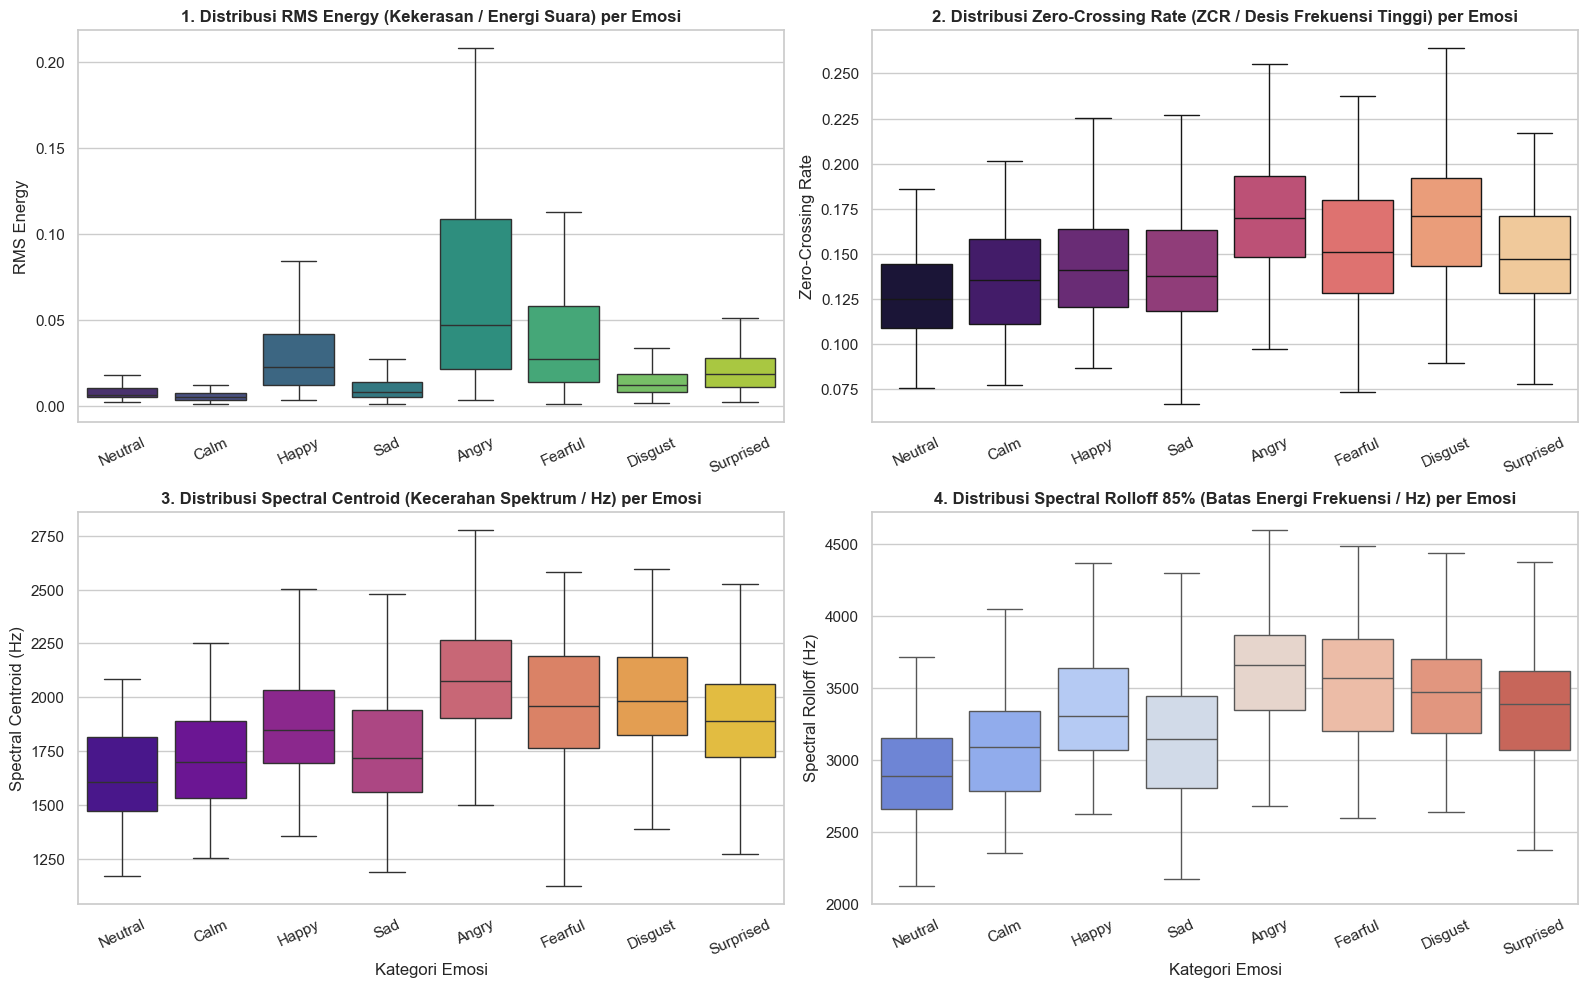

In [7]:
# Tabel ringkasan statistik fitur akustik per kelas emosi
acoustic_stats = df_full.groupby('emotion').agg(
    RMSE_Mean=('rmse', 'mean'),
    RMSE_Std=('rmse', 'std'),
    ZCR_Mean=('zcr', 'mean'),
    ZCR_Std=('zcr', 'std'),
    Centroid_Hz_Mean=('spectral_centroid_hz', 'mean'),
    Centroid_Hz_Std=('spectral_centroid_hz', 'std'),
    Rolloff_Hz_Mean=('spectral_rolloff_hz', 'mean'),
    Rolloff_Hz_Std=('spectral_rolloff_hz', 'std')
).loc[emotion_order].round(4)

print("=== RINGKASAN STATISTIK FITUR AKUSTIK PER KELAS EMOSI (1.440 SAMPEL) ===")
display(acoustic_stats)

# Visualisasi Boxplot 4 Fitur Akustik Utama pada 8 Kelas Emosi
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.boxplot(data=df_full, x='emotion', y='rmse', order=emotion_order, palette='viridis', ax=axes[0, 0], showfliers=False)
axes[0, 0].set_title('1. Distribusi RMS Energy (Kekerasan / Energi Suara) per Emosi')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('RMS Energy')
axes[0, 0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_full, x='emotion', y='zcr', order=emotion_order, palette='magma', ax=axes[0, 1], showfliers=False)
axes[0, 1].set_title('2. Distribusi Zero-Crossing Rate (ZCR / Desis Frekuensi Tinggi) per Emosi')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Zero-Crossing Rate')
axes[0, 1].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_full, x='emotion', y='spectral_centroid_hz', order=emotion_order, palette='plasma', ax=axes[1, 0], showfliers=False)
axes[1, 0].set_title('3. Distribusi Spectral Centroid (Kecerahan Spektrum / Hz) per Emosi')
axes[1, 0].set_xlabel('Kategori Emosi')
axes[1, 0].set_ylabel('Spectral Centroid (Hz)')
axes[1, 0].tick_params(axis='x', rotation=25)

sns.boxplot(data=df_full, x='emotion', y='spectral_rolloff_hz', order=emotion_order, palette='coolwarm', ax=axes[1, 1], showfliers=False)
axes[1, 1].set_title('4. Distribusi Spectral Rolloff 85% (Batas Energi Frekuensi / Hz) per Emosi')
axes[1, 1].set_xlabel('Kategori Emosi')
axes[1, 1].set_ylabel('Spectral Rolloff (Hz)')
axes[1, 1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'boxplot_fitur_akustik_8_emosi.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.7 Analisis Pengaruh Intensitas Emosi (*Normal vs Strong*) & Profil Koefisien MFCC

Metadata RAVDESS membedakan ekspresi emosi ke dalam dua tingkat intensitas: **Normal (`01`)** dan **Strong (`02`)** (kecuali *Neutral* yang hanya memiliki tingkat *Normal*). Selain itu, kita mengekstrak **40 koefisien MFCC (*Mel-Frequency Cepstral Coefficients*)** menggunakan *Discrete Cosine Transform* (DCT Tipe-II) untuk melihat perbedaan amplop spektral saluran vokal antar emosi.


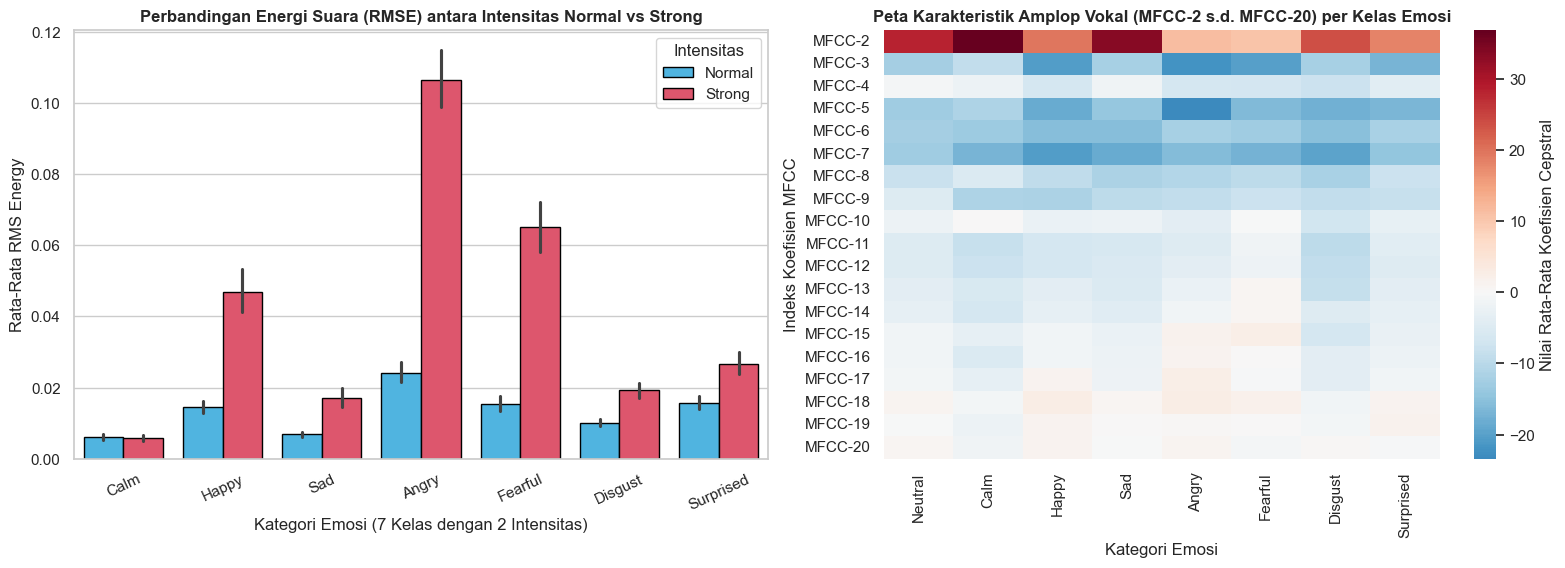

In [8]:
def compute_mfcc_40(y, n_mfcc=40):
    """Menghitung 40 koefisien MFCC dari Log Mel-Spectrogram menggunakan DCT Tipe-II."""
    log_mel = compute_log_mel_spectrogram(y)
    mfcc = dct(log_mel, type=2, axis=0, norm='ortho')[:n_mfcc, :]
    return mfcc

# Hitung rata-rata profil 20 koefisien MFCC pertama pada ke-8 kelas emosi (sampel representatif per kelas)
mfcc_profiles = {}
for emo in emotion_order:
    sub_paths = df_full[df_full['emotion'] == emo]['abs_path'].iloc[:24]
    mfcc_stack = []
    for p in sub_paths:
        y_3s = load_clean_3s_audio(p)
        y_norm = y_3s / (np.max(np.abs(y_3s)) + 1e-8)
        mfcc_mat = compute_mfcc_40(y_norm, n_mfcc=20)
        mfcc_stack.append(np.mean(mfcc_mat, axis=1))
    mfcc_profiles[emo] = np.mean(mfcc_stack, axis=0)

df_mfcc_profile = pd.DataFrame(mfcc_profiles, index=[f"MFCC-{i+1}" for i in range(20)])

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

# Plot 1: Perbandingan Log10(RMSE) antara Intensitas Normal vs Strong
df_full['log_rmse'] = np.log10(df_full['rmse'] + 1e-6)
sns.barplot(
    data=df_full[df_full['emotion'] != 'Neutral'],
    x='emotion', y='rmse', hue='intensity',
    order=[e for e in emotion_order if e != 'Neutral'],
    palette={'Normal': '#38bdf8', 'Strong': '#f43f5e'},
    edgecolor='black', ax=axes[0]
)
axes[0].set_title('Perbandingan Energi Suara (RMSE) antara Intensitas Normal vs Strong')
axes[0].set_xlabel('Kategori Emosi (7 Kelas dengan 2 Intensitas)')
axes[0].set_ylabel('Rata-Rata RMS Energy')
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title='Intensitas')

# Plot 2: Heatmap Rata-Rata Koefisien MFCC (MFCC-2 s.d. MFCC-20) Lintas 8 Kelas Emosi
sns.heatmap(
    df_mfcc_profile.iloc[1:, :], cmap='RdBu_r', center=0, annot=False,
    cbar_kws={'label': 'Nilai Rata-Rata Koefisien Cepstral'}, ax=axes[1]
)
axes[1].set_title('Peta Karakteristik Amplop Vokal (MFCC-2 s.d. MFCC-20) per Kelas Emosi')
axes[1].set_xlabel('Kategori Emosi')
axes[1].set_ylabel('Indeks Koefisien MFCC')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_IMAGE_DIR, 'intensitas_dan_mfcc_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()


---
## 2.8 Kesimpulan *Data Understanding* & Keterkaitan dengan Tahap *Data Preparation*

Berdasarkan hasil eksplorasi dan audit menyeluruh pada **1.440 file audio RAVDESS**, diperoleh kesimpulan ilmiah yang menjadi dasar eksekusi **Tahap 2 (Data Preparation)**:

1. **Integritas & Deduplikasi Data:**
   * Seluruh **1.440 file `.wav`** di dalam folder `dataset/Actor_01` s.d. `Actor_24` valid, bebas dari korupsi sinyal (`0 NaN/Inf`), dan telah dipisahkan dari folder duplikat `audio_speech_actors_01-24`.
   * Katalog metadata lengkap beserta statistik akustik dasar telah disimpan ke file `ravdess_data_understanding_catalog.csv`.
2. **Standarisasi Kanal & Frekuensi Sampling ($48\text{ kHz} \to 16\text{ kHz}$):**
   * Karena terdapat sebagian kecil file berformat Stereo (`2 kanal`) dan seluruh file direkam pada $48\text{ kHz}$, proses *Data Preparation* wajib melakukan konversi **Mono** dan *downsampling* ke **$16\text{ kHz}$**.
3. **Pemotongan Keheningan (*Silence Trimming*) & Durasi Tetap $3.0\text{ Detik}$:**
   * Rata-rata rekaman memiliki $\sim 32\%$ bagian hening di awal dan akhir kalimat. *Silence Trimming* pada ambang $\text{top\_db} = 25\text{ dB}$ memadatkan durasi rata-rata kalimat aktif ke $\sim 2,45\text{ detik}$, sehingga penyeragaman durasi ke **$3.0\text{ detik}$ ($48.000\text{ sampel}$)** sangat presisi tanpa memotong intonasi emosi.
4. **Penanganan *Class Imbalance* pada Kelas *Neutral*:**
   * Terbukti kelas **Neutral** hanya memiliki **96 sampel ($6,67\%$)** karena tidak memiliki variasi intensitas *Strong*, sedangkan 7 kelas lainnya masing-masing memiliki **192 sampel ($13,33\%$)**. Pada tahap *Data Preparation*, ketimpangan ini wajib diatasi dengan **Hybrid Class Balancing** (*2× Targeted Audio Augmentation Oversampling* pada kelas *Neutral* + *Inverse Class-Frequency Weighting* $w_{\text{Neutral}} = 1,875$).
5. **Kesiapan Fitur untuk Model *Attention-based CRNN*:**
   * Pola **Log Mel-Spectrogram**, **MFCC**, **RMSE**, **ZCR**, **Spectral Centroid**, dan **Spectral Rolloff** menunjukkan daya pisah fisik yang jelas antara kelompok emosi *High-Arousal* (*Angry, Happy, Surprised, Fearful*) dan *Low-Arousal* (*Calm, Sad, Neutral, Disgust*), sekaligus memperlihatkan tumpang-tindih lokal yang membutuhkan ekstraksi fitur spasio-temporal dari arsitektur **2D-CNN + Bi-LSTM + Multi-Head Self-Attention**.
